## 1. Imports and constants


In [73]:
import os
import sys
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.experimental import enable_halving_search_cv
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.utils import resample
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import HalvingGridSearchCV
from sklearn.model_selection import (
    TimeSeriesSplit, learning_curve, HalvingGridSearchCV
) # Added HalvingGridSearchCV
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    f1_score, precision_score, recall_score,
    roc_curve, roc_auc_score, precision_recall_curve, auc,
    brier_score_loss, log_loss,
)
from sklearn.calibration import calibration_curve, CalibratedClassifierCV

RANDOM_STATE = 42
TEST_CUTOFF = pd.Timestamp('2016-01-01')   # train < cutoff <= test


### Output setup

A `figures/` directory and an `LR_result.txt` file are created next to this notebook. `sys.stdout` is teed so every `print(...)` is mirrored to the results file. Each plot is saved with `save_fig(...)` before `plt.show()`.


In [74]:
import os
import sys
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve,
    auc,
    precision_recall_curve,
    log_loss,
    brier_score_loss,
    f1_score,
    precision_score,
    recall_score
)

# Create output directory
os.makedirs('../visualization/rf', exist_ok=True)

def save_fig(name, fig=None):
    """Save figure to visualization/rf directory."""
    if fig is None:
        fig = plt.gcf()
    path = f'../visualization/rf/{name}.png'
    fig.savefig(path, dpi=150, bbox_inches='tight')
    print(f'  [saved {path}]')

In [84]:
# Load preprocessed train/test data from 4_preprocessing_imputation.ipynb
X_train = pd.read_csv('../data/weatherAUS_X_train.csv')
X_test = pd.read_csv('../data/weatherAUS_X_test.csv')
y_train = pd.read_csv('../data/weatherAUS_y_train.csv').squeeze()
y_test = pd.read_csv('../data/weatherAUS_y_test.csv').squeeze()

print(f'Loaded preprocessed data:')
print(f'X_train: {X_train.shape}')
print(f'X_test: {X_test.shape}')
print(f'y_train: {y_train.shape}')
print(f'y_test: {y_test.shape}')
print(f'\nData already includes:')
print(f'  - MICE imputation for missing values')
print(f'  - Cyclic encoding of wind directions (sin/cos)')
print(f'  - Categorical encoding (LabelEncoder)')
print(f'  - Chronological train/test split (cutoff: 2016-01-01)')

Loaded preprocessed data:
X_train: (113506, 23)
X_test: (25314, 23)
y_train: (113506,)
y_test: (25314,)

Data already includes:
  - MICE imputation for missing values
  - Cyclic encoding of wind directions (sin/cos)
  - Categorical encoding (LabelEncoder)
  - Chronological train/test split (cutoff: 2016-01-01)


## 5. Random Forest Model Hyperparameter Tuning and Training

In [76]:
tscv = TimeSeriesSplit(n_splits=3) # Reduced splits for a quicker demonstration

# Define the base Random Forest Classifier model
# Using n_jobs=-1 to utilize all available cores
rf_base_model = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)

# Define the highly reduced parameter grid for GridSearchCV
param_grid = {
    'n_estimators': [50, 100], # Two reasonable options
    'max_features': ['sqrt'],  # A single common option
    'max_depth': [10, 20],   # Two depth options
    'min_samples_split': [5]   # A single option
}

print(f"Parameter grid size: {np.prod([len(v) for v in param_grid.values()])} combinations")

Parameter grid size: 4 combinations


In [77]:
# Initialize HalvingGridSearchCV for faster hyperparameter tuning
# We will use 'roc_auc' as the primary scoring metric for refitting the best model
# Set return_train_score=True to get training scores for analysis
# min_resources='auto' automatically determines the minimum number of samples for the first iteration
# factor=2 will halve the candidates at each iteration, or double the resources for the best ones
grid_search = HalvingGridSearchCV(
    estimator=rf_base_model,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=tscv,
    refit='roc_auc',
    verbose=2,
    return_train_score=True,
    n_jobs=-1, # Use all available cores for parallel processing
    factor=2, # Halve candidates/double resources at each step
    min_resources='exhaust' # Automatically determine min resources for the first fold
)

print("Starting Random Forest HalvingGrid Search...")
# Fit HalvingGridSearchCV to the training data
grid_search.fit(X_train, y_train)
print("Random Forest HalvingGrid Search completed.")

# Get the best model
best_rf_model = grid_search.best_estimator_

print(f"\nBest parameters found: {grid_search.best_params_}")
print(f"Best ROC AUC score during cross-validation: {grid_search.best_score_:.4f}")

Starting Random Forest HalvingGrid Search...
n_iterations: 3
n_required_iterations: 3
n_possible_iterations: 3
min_resources_: 28376
max_resources_: 113506
aggressive_elimination: False
factor: 2
----------
iter: 0
n_candidates: 4
n_resources: 28376
Fitting 3 folds for each of 4 candidates, totalling 12 fits
----------
iter: 1
n_candidates: 2
n_resources: 56752
Fitting 3 folds for each of 2 candidates, totalling 6 fits
----------
iter: 2
n_candidates: 1
n_resources: 113504
Fitting 3 folds for each of 1 candidates, totalling 3 fits
Random Forest HalvingGrid Search completed.

Best parameters found: {'max_depth': 10, 'max_features': 'sqrt', 'min_samples_split': 5, 'n_estimators': 100}
Best ROC AUC score during cross-validation: 0.8688


In [85]:
# Make predictions on the training set using the best model
y_pred_rf_train = best_rf_model.predict(X_train)
y_proba_rf_train = best_rf_model.predict_proba(X_train)[:, 1]

print("\n--- Classification Report (Train Set) ---")
print(classification_report(y_train, y_pred_rf_train))

print("\n--- Additional Metrics (Train Set) ---")
print(f"ROC AUC Score: {roc_auc_score(y_train, y_proba_rf_train):.4f}")

precision_train, recall_train, _ = precision_recall_curve(y_train, y_proba_rf_train)
pr_auc_train = auc(recall_train, precision_train)
print(f"Precision-Recall AUC Score: {pr_auc_train:.4f}")


--- Classification Report (Train Set) ---
              precision    recall  f1-score   support

           0       0.88      0.97      0.92     88583
           1       0.84      0.52      0.64     24923

    accuracy                           0.87    113506
   macro avg       0.86      0.75      0.78    113506
weighted avg       0.87      0.87      0.86    113506


--- Additional Metrics (Train Set) ---
ROC AUC Score: 0.9094
Precision-Recall AUC Score: 0.7868


## 6. Random Forest Model Evaluation on Test Set


6. Random Forest Model Evaluation on Test Set



--- Classification Report (Test Set) ---
              precision    recall  f1-score   support

           0       0.86      0.95      0.90     19569
           1       0.74      0.47      0.58      5745

    accuracy                           0.84     25314
   macro avg       0.80      0.71      0.74     25314
weighted avg       0.83      0.84      0.83     25314


--- Additional Metrics (Test Set) ---
ROC AUC Score: 0.8616
Log Loss: 0.3650
Brier Score Loss: 0.1134
  [saved ../visualization/rf/rf_confusion_matrix.png]


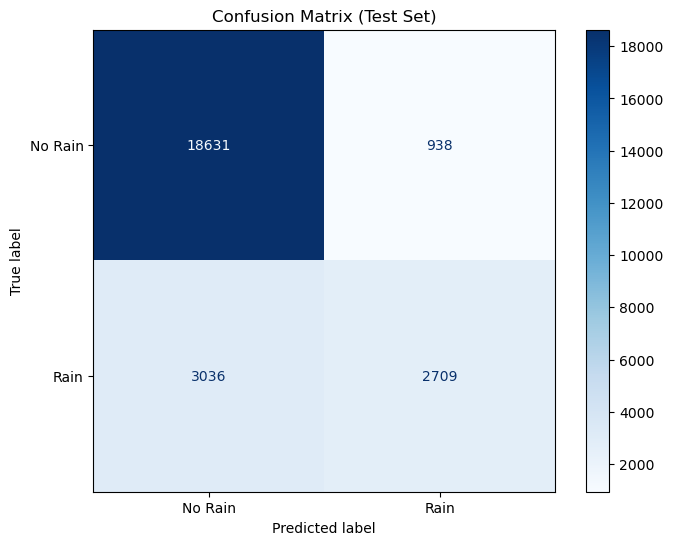

In [79]:
log_section('6. Random Forest Model Evaluation on Test Set')

# Make predictions on the test set using the best model
y_pred_rf = best_rf_model.predict(X_test_scaled)
y_proba_rf = best_rf_model.predict_proba(X_test_scaled)[:, 1]

print("\n--- Classification Report (Test Set) ---")
print(classification_report(y_test, y_pred_rf))

print("\n--- Additional Metrics (Test Set) ---")
print(f"ROC AUC Score: {roc_auc_score(y_test, y_proba_rf):.4f}")
print(f"Log Loss: {log_loss(y_test, y_proba_rf):.4f}")
print(f"Brier Score Loss: {brier_score_loss(y_test, y_proba_rf):.4f}")

# Confusion Matrix
fig, ax = plt.subplots(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred_rf, labels=best_rf_model.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Rain', 'Rain'])
disp.plot(cmap=plt.cm.Blues, ax=ax)
plt.title('Confusion Matrix (Test Set)')
save_fig('rf_confusion_matrix')
plt.show()

  [saved ../visualization/rf/rf_roc_curve.png]


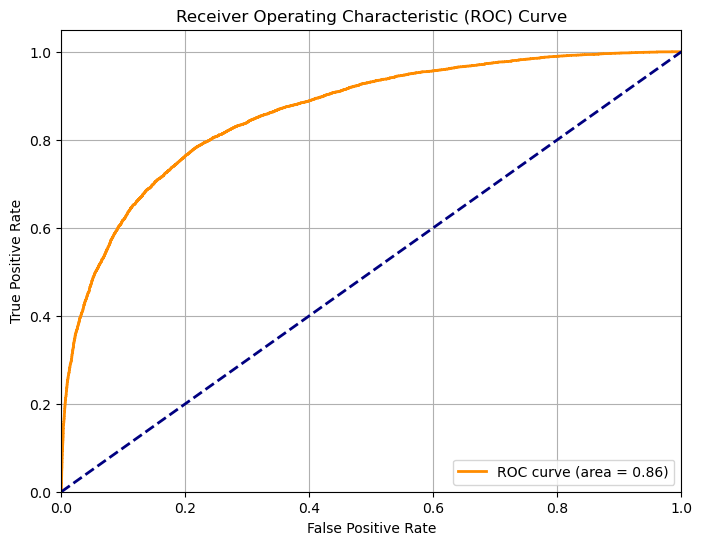

In [80]:
# ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_proba_rf)
roc_auc = auc(fpr, tpr)

fig = plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.grid(True)
save_fig('rf_roc_curve')
plt.show()

  [saved ../visualization/rf/rf_precision_recall_curve.png]


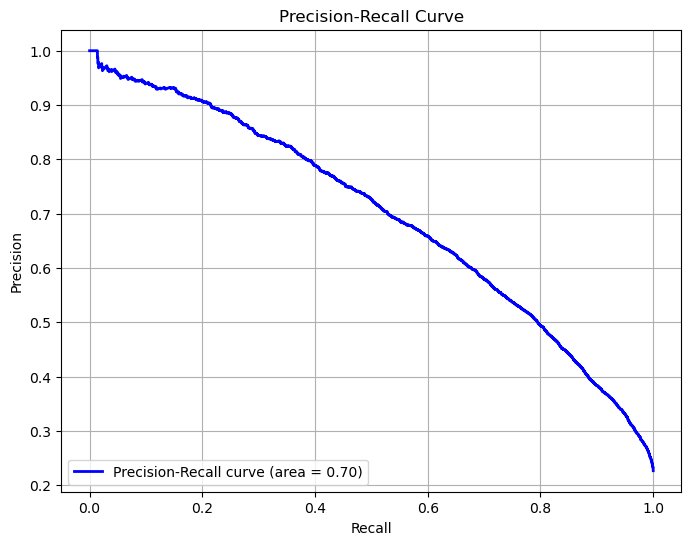

In [81]:
# Precision-Recall Curve
precision, recall, _ = precision_recall_curve(y_test, y_proba_rf)
pr_auc = auc(recall, precision)

fig = plt.figure(figsize=(8, 6))
plt.plot(recall, precision, color='blue', lw=2, label=f'Precision-Recall curve (area = {pr_auc:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc='lower left')
plt.grid(True)
save_fig('rf_precision_recall_curve')
plt.show()

  [saved ../visualization/rf/rf_calibration_curve.png]


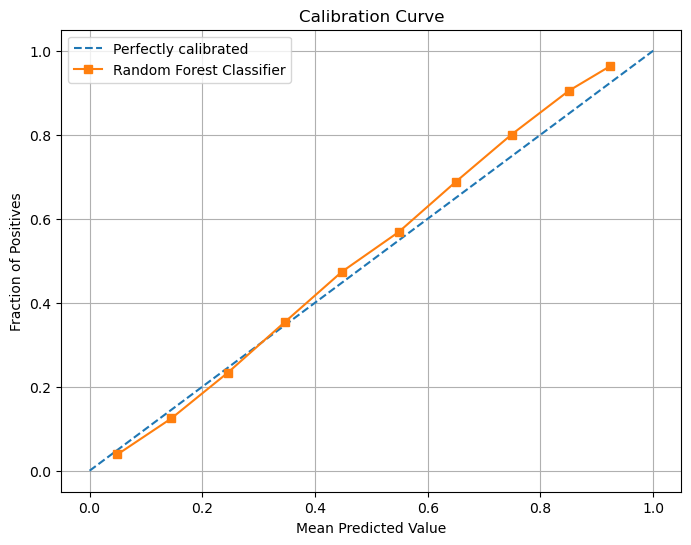

In [82]:
# Calibration Curve
fop, mpv = calibration_curve(y_test, y_proba_rf, n_bins=10, strategy='uniform')

fig = plt.figure(figsize=(8, 6))
plt.plot([0, 1], [0, 1], linestyle='--', label='Perfectly calibrated')
plt.plot(mpv, fop, 's-', label='Random Forest Classifier')
plt.xlabel('Mean Predicted Value')
plt.ylabel('Fraction of Positives')
plt.title('Calibration Curve')
plt.legend(loc='upper left')
plt.grid(True)
save_fig('rf_calibration_curve')
plt.show()

## 7. Model Saving

In [83]:
log_section('7. Saving the Random Forest Model')

import pickle

model_filename = 'best_random_forest_model.pkl'
with open(model_filename, 'wb') as file:
    pickle.dump(best_rf_model, file)

print(f"Random Forest model saved to: {model_filename}")


7. Saving the Random Forest Model


Random Forest model saved to: best_random_forest_model.pkl
